###  **Title: DSC670-T301 Advanced Uses of Generative AI (2271-1)**
####  **Professor:** *Frank Neugebauer*
####  **Date: 01 Oct 2026**
####  **Author:** *Akhil Anand Thazhaniyil Muralidharan*
####  **Description:** Milestone 2 : Fine Tuning a LLM for Telecom Plan Selection and Billing Assistance.

*************

### Refined Problem Statement

Telecom customers often need help selecting a plan or interpreting charges. A useful assistant must do more than produce fluent answers. It must use only the catalog or billing facts supplied in the prompt, respect budget and usage constraints, explain recommendations in plain language, identify tradeoffs, and avoid inventing prices or account details.

The main research question is: **Does parameter-efficient supervised fine-tuning improve response consistency and groundedness compared with the same base model using prompting alone?**
**********

### Import Required Libraries


In [12]:
import json
import random
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

SEED = 42
random.seed(SEED)

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Base model:", MODEL_NAME)
print("Output directory:", OUTPUT_DIR.resolve())

Base model: Qwen/Qwen2.5-0.5B-Instruct
Output directory: /Users/athazh341@apac.comcast.com/Library/CloudStorage/OneDrive-Comcast/AkhilAnandTM/BVU/DSC670/Assignments/Week4/output


### Data Setup

The project does not use proprietary customer or company data. The following catalog is synthetic and exists only to test grounded reasoning. Prices and features are fictional. Keeping the facts inside the notebook makes it possible to verify whether a response used the supplied evidence or invented information.


In [13]:
plan_catalog = pd.DataFrame([
    {"plan": "Connect 200", "monthly_price": 45, "download_mbps": 200, "upload_mbps": 10, "data_allowance": "1.2 TB"},
    {"plan": "Work 500", "monthly_price": 70, "download_mbps": 500, "upload_mbps": 50, "data_allowance": "1.2 TB"},
    {"plan": "Gig 1000", "monthly_price": 95, "download_mbps": 1000, "upload_mbps": 100, "data_allowance": "Unlimited"},
    {"plan": "Family 500", "monthly_price": 85, "download_mbps": 500, "upload_mbps": 50, "data_allowance": "1.2 TB"},
    {"plan": "Family Gig", "monthly_price": 105, "download_mbps": 1000, "upload_mbps": 100, "data_allowance": "Unlimited"},
    {"plan": "Premium Gig", "monthly_price": 130, "download_mbps": 1000, "upload_mbps": 100, "data_allowance": "Unlimited + equipment bundle"},
])
plan_catalog


,plan,monthly_price,download_mbps,upload_mbps,data_allowance
0,Connect 200,45,200,10,1.2 TB
1,Work 500,70,500,50,1.2 TB
2,Gig 1000,95,1000,100,Unlimited
3,Family 500,85,500,50,1.2 TB
4,Family Gig,105,1000,100,Unlimited
5,Premium Gig,130,1000,100,Unlimited + equipment bundle


### Prompts

* The system prompt establishes stable behavior expected from both the base and tuned model. 
* The response format makes evaluation easier because each answer should contain the same five sections.
* The five experiments cover different failure modes rather than repeating one recommendation task.


In [14]:
SYSTEM_PROMPT = """You are a telecom plan and billing assistant.
Use only facts explicitly supplied by the user.
Do not invent prices, fees, promotions, taxes, policies, account activity, or plan features.
If information is insufficient, ask concise follow-up questions instead of guessing.
Use these headings when applicable:
1. Customer need
2. Recommendation or explanation
3. Evidence
4. Tradeoff or uncertainty
5. Next step
Keep the answer clear and customer-friendly."""

experiments = [
    {
        "id": 1,
        "name": "Remote worker plan recommendation",
        "prompt": """Available plans: Connect 200 costs $45 per month with 200 Mbps download and 10 Mbps upload; Work 500 costs $70 with 500 Mbps download and 50 Mbps upload; Gig 1000 costs $95 with 1,000 Mbps download and 100 Mbps upload. A customer works remotely, attends video meetings for eight hours per day, has two household members, uses ten devices, and has a maximum budget of $75. Recommend one plan, explain why, identify one tradeoff, and do not invent fees or promotions.""",
        "tests": "budget, upload requirement, justified recommendation"
    },
    {
        "id": 2,
        "name": "Confirmed promotional credit expiration",
        "prompt": """A customer's bill increased from $80 to $100. The provided bill shows that a $20 promotional credit ended this month. No other charge changed. Explain the increase in simple language, distinguish confirmed facts from possibilities, and give one next step.""",
        "tests": "billing groundedness and avoidance of speculation"
    },
    {
        "id": 3,
        "name": "Family bundle comparison",
        "prompt": """A family of four streams 4K video on three televisions, has two online gamers, uses approximately 900 GB per month, and wants to stay below $110. Compare Family 500 at $85 with 1.2 TB data, Family Gig at $105 with unlimited data, and Premium Gig at $130 with unlimited data and an equipment bundle. Recommend one option and explain the tradeoff.""",
        "tests": "multiple constraints and over-selection risk"
    },
    {
        "id": 4,
        "name": "Prorated charge explanation",
        "prompt": """A customer upgraded service on the twentieth day of a thirty-day billing cycle. The bill includes a credit for ten unused days of the old plan and a charge for ten days of the new plan. Explain prorated billing in plain language without assuming any additional fees.""",
        "tests": "plain-language concept explanation"
    },
    {
        "id": 5,
        "name": "Insufficient information",
        "prompt": """A customer says, 'My internet is slow. Tell me exactly which plan I should buy.' No speed test, device count, usage pattern, budget, or current plan is provided. Ask the minimum useful follow-up questions and do not recommend a specific plan yet.""",
        "tests": "uncertainty recognition and responsible refusal"
    }
]

pd.DataFrame(experiments)[["id", "name", "tests"]]


,id,name,tests
0,1,Remote worker plan recommendation,"budget, upload requirement, justified recommen..."
1,2,Confirmed promotional credit expiration,billing groundedness and avoidance of speculation
2,3,Family bundle comparison,multiple constraints and over-selection risk
3,4,Prorated charge explanation,plain-language concept explanation
4,5,Insufficient information,uncertainty recognition and responsible refusal


### Visualization

This visualization does not claim model performance. It shows which capability each prompt is designed to test. The chart helps demonstrate that the experiment set covers recommendation reasoning, billing explanation, groundedness, uncertainty handling, and customer communication.


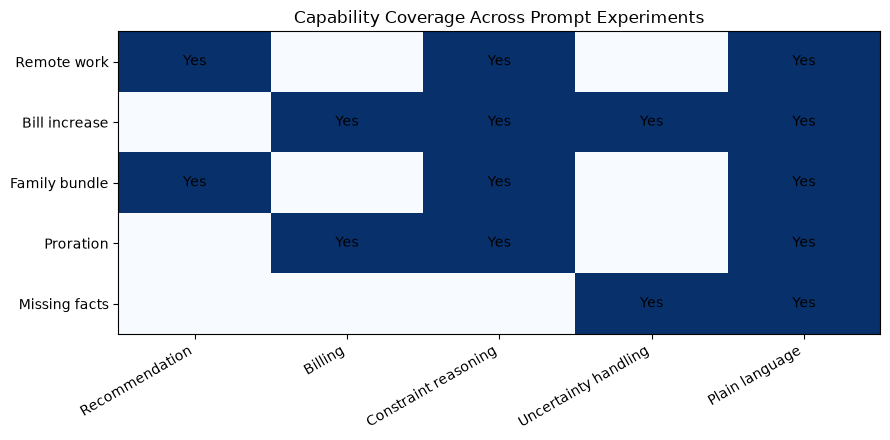

In [15]:
coverage = pd.DataFrame({
    "Experiment": ["Remote work", "Bill increase", "Family bundle", "Proration", "Missing facts"],
    "Recommendation": [1, 0, 1, 0, 0],
    "Billing": [0, 1, 0, 1, 0],
    "Constraint reasoning": [1, 1, 1, 1, 0],
    "Uncertainty handling": [0, 1, 0, 0, 1],
    "Plain language": [1, 1, 1, 1, 1],
}).set_index("Experiment")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.imshow(coverage.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(coverage.columns)), coverage.columns, rotation=30, ha="right")
ax.set_yticks(range(len(coverage.index)), coverage.index)
ax.set_title("Capability Coverage Across Prompt Experiments")
for i in range(coverage.shape[0]):
    for j in range(coverage.shape[1]):
        ax.text(j, i, "Yes" if coverage.iloc[i, j] else "", ha="center", va="center")
plt.tight_layout()
plt.show()


### Load the Base Model and Run the Five Prompts

The next cells download the model and generate one response per experiment. Generation uses deterministic settings to make the baseline easier to reproduce.


In [16]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto"
)
model.eval()
print("Model loaded on:", model.device)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Model loaded on: mps:0


In [17]:
def generate_response(model, tokenizer, user_prompt, max_new_tokens=150):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_prompt},
    ]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )
    generated = output_ids[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(generated, skip_special_tokens=True).strip()

base_results = []
for item in experiments:
    response = generate_response(model, tokenizer, item["prompt"])
    base_results.append({**item, "model": "Base", "response": response})
    print(f"\n--- Experiment {item['id']}: {item['name']} ---\n{response}\n")

base_results_df = pd.DataFrame(base_results)
base_results_df.to_csv(OUTPUT_DIR / "base_prompt_results.csv", index=False)
base_results_df[["id", "name", "response"]]


--- Experiment 1: Remote worker plan recommendation ---
Based on your requirements, I recommend the **Work 500** plan.

### Explanation:

- **Cost**: The Work 500 plan offers a lower monthly cost compared to the other options. It costs $70 per month, which is significantly cheaper than the Connect 200 at $45 per month and the Gig 1000 at $95 per month.
  
- **Features**: While both the Work 500 and Gig 1000 offer high-speed internet access (500 Mbps download and 50 Mbps upload), the Work 500 includes additional benefits such as unlimited data usage up to 1,000 Mbps, which can be beneficial if you


--- Experiment 2: Confirmed promotional credit expiration ---
The increase in your bill from $80 to $100 could be due to several reasons such as an unexpected expense, a sale on a product you didn't purchase, or a change in your subscription plans. Since no other charges have altered, it might be worth checking if there was any additional spending during the month that wasn’t recorded.

Nex

,id,name,response
0,1,Remote worker plan recommendation,"Based on your requirements, I recommend the **..."
1,2,Confirmed promotional credit expiration,The increase in your bill from $80 to $100 cou...
2,3,Family bundle comparison,Recommendation: **Family Gig**\n\n**Tradeoff:*...
3,4,Prorated charge explanation,The customer's upgrade has been prorated based...
4,5,Insufficient information,Could you please provide more details about yo...


## 7. Commentary and Human Evaluation

Automated text-overlap metrics are not sufficient for this task because several answers may be phrased differently while still being correct. A human rubric is more appropriate for the first milestone evaluation. Review each answer and enter scores from 1 to 5:

- **Groundedness:** Uses only supplied facts.
- **Relevance:** Addresses the actual customer need and constraints.
- **Clarity:** Uses understandable language and organization.
- **Completeness:** Includes all requested elements.
- **Safety:** Avoids fabricated account or plan claims and handles uncertainty appropriately.

The score template starts empty on purpose. This prevents expected outcomes from being presented as observed results.


In [20]:
score_columns = ["groundedness", "relevance", "clarity", "completeness", "safety"]

scores = pd.DataFrame([
    {
        "id": 1,
        "name": "Remote worker plan recommendation",
        "model": "Base",
        "groundedness": 2,
        "relevance": 4,
        "clarity": 3,
        "completeness": 2,
        "safety": 2,
        "review_notes": "Recommends the suitable in-budget plan, but incorrectly calls $70 cheaper than $45 and invents unlimited data and additional benefits.",
    },
    {
        "id": 2,
        "name": "Confirmed promotional credit expiration",
        "model": "Base",
        "groundedness": 1,
        "relevance": 2,
        "clarity": 3,
        "completeness": 2,
        "safety": 1,
        "review_notes": "Misses the confirmed $20 promotional-credit expiration and invents unrelated possible expenses instead of explaining the supplied fact.",
    },
    {
        "id": 3,
        "name": "Family bundle comparison",
        "model": "Base",
        "groundedness": 1,
        "relevance": 3,
        "clarity": 2,
        "completeness": 3,
        "safety": 1,
        "review_notes": "Selects an option within budget, but contradicts the listed prices and invents streaming and premium-content benefits.",
    },
    {
        "id": 4,
        "name": "Prorated charge explanation",
        "model": "Base",
        "groundedness": 2,
        "relevance": 3,
        "clarity": 2,
        "completeness": 2,
        "safety": 2,
        "review_notes": "Attempts a plain-language explanation but reverses the timing and incorrectly describes how the old-plan credit and new-plan charge apply.",
    },
    {
        "id": 5,
        "name": "Insufficient information",
        "model": "Base",
        "groundedness": 5,
        "relevance": 5,
        "clarity": 5,
        "completeness": 4,
        "safety": 5,
        "review_notes": "Correctly avoids recommending a plan and asks useful questions, though it omits an explicit budget and current-plan question.",
    },
])

scores

,id,name,model,groundedness,relevance,clarity,completeness,safety,review_notes
0,1,Remote worker plan recommendation,Base,2,4,3,2,2,"Recommends the suitable in-budget plan, but in..."
1,2,Confirmed promotional credit expiration,Base,1,2,3,2,1,Misses the confirmed $20 promotional-credit ex...
2,3,Family bundle comparison,Base,1,3,2,3,1,"Selects an option within budget, but contradic..."
3,4,Prorated charge explanation,Base,2,3,2,2,2,Attempts a plain-language explanation but reve...
4,5,Insufficient information,Base,5,5,5,4,5,Correctly avoids recommending a plan and asks ...


,id,name,model,groundedness,relevance,clarity,completeness,safety,review_notes,total
0,1,Remote worker plan recommendation,Base,2,4,3,2,2,"Recommends the suitable in-budget plan, but in...",13
1,2,Confirmed promotional credit expiration,Base,1,2,3,2,1,Misses the confirmed $20 promotional-credit ex...,9
2,3,Family bundle comparison,Base,1,3,2,3,1,"Selects an option within budget, but contradic...",10
3,4,Prorated charge explanation,Base,2,3,2,2,2,Attempts a plain-language explanation but reve...,11
4,5,Insufficient information,Base,5,5,5,4,5,Correctly avoids recommending a plan and asks ...,24


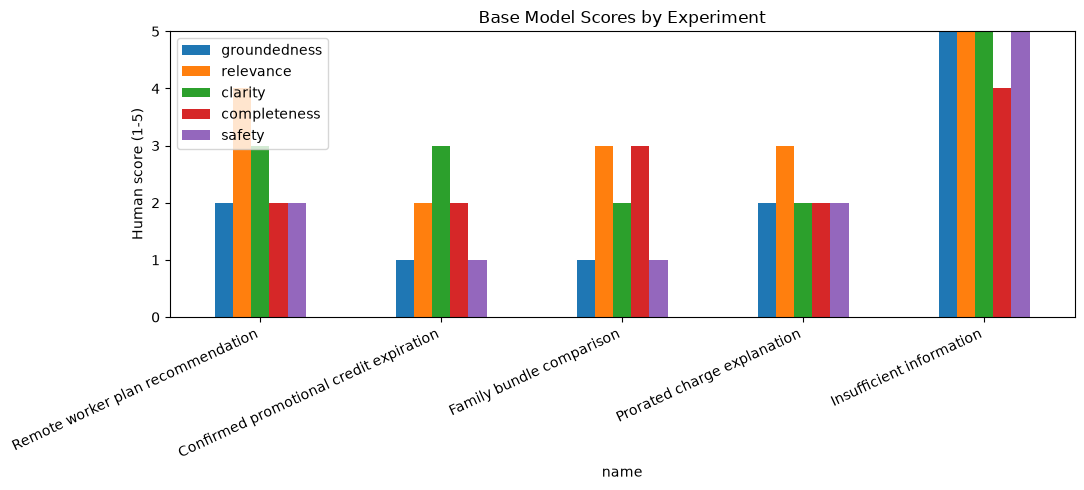

In [22]:
def validate_scores(df):
    numeric = df[score_columns].apply(pd.to_numeric, errors="coerce")
    invalid = numeric.notna() & ~(numeric.ge(1) & numeric.le(5))
    if invalid.any().any():
        raise ValueError("All entered rubric scores must be between 1 and 5.")
    return numeric

numeric_scores = validate_scores(scores)
if numeric_scores.notna().all().all():
    scores[score_columns] = numeric_scores
    scores["total"] = scores[score_columns].sum(axis=1)
    display(scores)

    ax = scores.plot(x="name", y=score_columns, kind="bar", figsize=(11, 5))
    ax.set_ylabel("Human score (1-5)")
    ax.set_title("Base Model Scores by Experiment")
    ax.set_ylim(0, 5)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Enter all human rubric scores to create the performance visualization.")

## 8. Create Initial Supervised Fine-Tuning Examples

The training examples below are deliberately different from the five evaluation prompts. Each answer demonstrates the desired behavior and structure. For a final training run, this starter set should be expanded with diverse, reviewed scenarios. Real customer data and personally identifiable information should not be added.


In [ ]:
training_examples = [
    {
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": "Plans: Basic 100 is $35 with 100/10 Mbps; Plus 300 is $55 with 300/25 Mbps. I live alone, stream HD most evenings, work from home two days weekly, and can spend $60. Recommend one plan."},
            {"role": "assistant", "content": "1. Customer need\nYou need reliable service for HD streaming and occasional remote work within a $60 budget.\n\n2. Recommendation or explanation\nPlus 300 is the stronger fit.\n\n3. Evidence\nIt costs $55, remains within budget, and provides 300 Mbps download and 25 Mbps upload compared with Basic 100.\n\n4. Tradeoff or uncertainty\nIt costs $20 more than Basic 100. The prompt does not provide data allowances or equipment charges, so I cannot compare those items.\n\n5. Next step\nConfirm whether both plans have the same data and equipment terms before changing service."}
        ]
    },
    {
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": "My bill changed from $65 to $75. The statement shows a new $10 modem rental charge and no other changes. Explain it."},
            {"role": "assistant", "content": "1. Customer need\nYou want to understand a $10 monthly increase.\n\n2. Recommendation or explanation\nThe increase is explained by the new modem rental charge.\n\n3. Evidence\nThe bill rose from $65 to $75, which is a $10 difference, and the statement lists a new $10 modem rental charge.\n\n4. Tradeoff or uncertainty\nNo other change is shown in the information provided. I cannot determine why the rental began without account details.\n\n5. Next step\nCheck whether you recently changed equipment or contact billing support to verify the rental start date."}
        ]
    },
    {
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": "I need the cheapest plan for my household."},
            {"role": "assistant", "content": "1. Customer need\nYou want the lowest-cost plan that still meets household needs.\n\n2. Recommendation or explanation\nI do not have enough information to recommend a specific plan.\n\n3. Evidence\nNo plan list, budget, household size, device count, or usage pattern was provided.\n\n4. Tradeoff or uncertainty\nChoosing only by price could result in insufficient speed or an unsuitable data allowance.\n\n5. Next step\nPlease provide the available plans, maximum budget, number of users and devices, and whether the household streams, games, or works remotely."}
        ]
    },
    {
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": "The bill gives a $15 credit because service was unavailable, followed by the normal $90 monthly service charge. What is the net service amount before taxes?"},
            {"role": "assistant", "content": "1. Customer need\nYou want the net service amount before taxes.\n\n2. Recommendation or explanation\nThe net amount is $75.\n\n3. Evidence\nThe normal $90 charge minus the $15 credit equals $75.\n\n4. Tradeoff or uncertainty\nTaxes and any other charges are not included because they were not provided.\n\n5. Next step\nCompare the $75 service subtotal with the statement before adding listed taxes or fees."}
        ]
    },
    {
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": "Plans: Stream 300 is $60 with 300 Mbps and 1 TB data; Stream 600 is $80 with 600 Mbps and unlimited data. We use about 1.1 TB monthly and our budget is $85."},
            {"role": "assistant", "content": "1. Customer need\nYour household uses about 1.1 TB monthly and needs a plan below $85.\n\n2. Recommendation or explanation\nStream 600 is the better fit.\n\n3. Evidence\nIt costs $80, stays within budget, and includes unlimited data. Stream 300 includes only 1 TB, which is below the stated usage.\n\n4. Tradeoff or uncertainty\nStream 600 costs $20 more each month. No information was provided about equipment, contracts, or temporary promotions.\n\n5. Next step\nConfirm the plan terms and whether the listed price includes required equipment."}
        ]
    }
]

train_path = OUTPUT_DIR / "telecom_train.jsonl"
with train_path.open("w", encoding="utf-8") as f:
    for record in training_examples:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print(f"Wrote {len(training_examples)} starter examples to {train_path}")


## 9. Validate the Training Data

The validation step catches simple but damaging dataset problems before training begins. It checks message roles, empty content, duplicate conversations, and example length. This is intentionally done early because troubleshooting a dataset after a long training run wastes time and compute.


In [ ]:
def validate_training_examples(records, tokenizer=None):
    allowed_roles = {"system", "user", "assistant"}
    seen = set()
    report = []

    for idx, record in enumerate(records):
        issues = []
        messages = record.get("messages", [])
        if not messages:
            issues.append("missing messages")
        for message in messages:
            if message.get("role") not in allowed_roles:
                issues.append(f"invalid role: {message.get('role')}")
            if not str(message.get("content", "")).strip():
                issues.append("empty content")
        signature = json.dumps(messages, sort_keys=True)
        if signature in seen:
            issues.append("duplicate conversation")
        seen.add(signature)

        token_count = None
        if tokenizer is not None and messages:
            rendered = tokenizer.apply_chat_template(messages, tokenize=False)
            token_count = len(tokenizer(rendered)["input_ids"])
        report.append({"example": idx + 1, "issues": "; ".join(issues) or "none", "tokens": token_count})

    return pd.DataFrame(report)

validation_report = validate_training_examples(training_examples, tokenizer)
validation_report


## 10. Optional Early LoRA Fine-Tuning

Run this section only in a GPU-enabled environment. The starter dataset proves that the pipeline works, but it is too small to support a strong final claim. Expand and review the dataset before the final training run. The initial configuration is intentionally modest so problems appear early and adjustments can be made.


In [7]:
# Set to True only when a GPU runtime is available and you are ready to train.
RUN_FINE_TUNING = False


In [ ]:
if RUN_FINE_TUNING:
    import torch
    from datasets import Dataset
    from peft import LoraConfig
    from transformers import AutoModelForCausalLM, AutoTokenizer
    from trl import SFTConfig, SFTTrainer

    ft_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    if ft_tokenizer.pad_token is None:
        ft_tokenizer.pad_token = ft_tokenizer.eos_token

    ft_model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
        device_map="auto",
    )
    ft_model.config.use_cache = False

    dataset_rows = []
    for record in training_examples:
        formatted = ft_tokenizer.apply_chat_template(
            record["messages"], tokenize=False, add_generation_prompt=False
        )
        dataset_rows.append({"text": formatted})
    train_dataset = Dataset.from_list(dataset_rows)

    peft_config = LoraConfig(
        r=8,
        lora_alpha=16,
        lora_dropout=0.05,
        bias="none",
        task_type="CAUSAL_LM",
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
    )

    training_args = SFTConfig(
        output_dir=str(OUTPUT_DIR / "checkpoints"),
        num_train_epochs=1,
        per_device_train_batch_size=1,
        gradient_accumulation_steps=4,
        learning_rate=2e-4,
        logging_steps=1,
        save_strategy="epoch",
        report_to="none",
        seed=SEED,
        fp16=torch.cuda.is_available(),
        dataset_text_field="text",
    )

    trainer = SFTTrainer(
        model=ft_model,
        args=training_args,
        train_dataset=train_dataset,
        peft_config=peft_config,
        processing_class=ft_tokenizer,
    )
    train_result = trainer.train()
    trainer.save_model(str(OUTPUT_DIR / "telecom_lora_adapter"))
    print(train_result)
else:
    print("Fine-tuning skipped. Set RUN_FINE_TUNING=True in a GPU runtime when ready.")

Fine-tuning skipped. Set RUN_FINE_TUNING=True in a GPU runtime when ready.


## 11. Evaluate a Trained Adapter

After training, reload the base model with the saved adapter and rerun the same five prompts. Do not reuse the training examples as evidence of improvement. The milestone prompts are held out from the starter training data so they can provide an initial comparison.


In [10]:
RUN_TUNED_EVALUATION = False
ADAPTER_PATH = OUTPUT_DIR / "telecom_lora_adapter"

if RUN_TUNED_EVALUATION:
    from peft import PeftModel
    tuned_base = AutoModelForCausalLM.from_pretrained(MODEL_NAME, torch_dtype="auto", device_map="auto")
    tuned_model = PeftModel.from_pretrained(tuned_base, str(ADAPTER_PATH))
    tuned_model.eval()

    tuned_results = []
    for item in experiments:
        response = generate_response(tuned_model, tokenizer, item["prompt"])
        tuned_results.append({**item, "model": "LoRA tuned", "response": response})
        print(f"\n--- Tuned Experiment {item['id']}: {item['name']} ---\n{response}\n")

    tuned_results_df = pd.DataFrame(tuned_results)
    tuned_results_df.to_csv(OUTPUT_DIR / "tuned_prompt_results.csv", index=False)
else:
    print("Tuned evaluation skipped. Train or provide an adapter, then set RUN_TUNED_EVALUATION=True.")


Tuned evaluation skipped. Train or provide an adapter, then set RUN_TUNED_EVALUATION=True.


## 12. Base-versus-Tuned Visualization

After scoring both sets of responses, place the scores in one dataframe. The visualization compares observed human scores only. It should not be created from estimated or expected values.


In [ ]:
# Expected input columns: id, name, model, groundedness, relevance, clarity, completeness, safety
# Example workflow after scoring:
combined_scores = pd.concat([base_scores, tuned_scores], ignore_index=True)

if "combined_scores" in globals():
    numeric = validate_scores(combined_scores)
    if numeric.notna().all().all():
        combined_scores[score_columns] = numeric
        summary = combined_scores.groupby("model")[score_columns].mean()
        ax = summary.T.plot(kind="bar", figsize=(10, 5))
        ax.set_ylabel("Average human score (1-5)")
        ax.set_title("Base Model vs. LoRA-Tuned Model")
        ax.set_ylim(0, 5)
        plt.xticks(rotation=25, ha="right")
        plt.tight_layout()
        plt.show()
    else:
        print("Complete all scores before plotting.")
else:
    print("Create combined_scores after evaluating and scoring both model versions.")


Create combined_scores after evaluating and scoring both model versions.


## 13. Reflection Template

Complete this section after running the notebook:

1. **What the base model did well:** Identify concrete strengths and quote short response excerpts.
2. **Where the base model failed:** Note unsupported claims, missed constraints, unclear explanations, or unnecessary recommendations.
3. **What changed after tuning:** Compare the same dimensions rather than relying on general impressions.
4. **Unexpected behavior:** Record any repetition, formatting errors, overfitting, or reduced general ability.
5. **Next adjustment:** State whether the prompt, dataset, rubric, LoRA settings, or model choice should change.

A useful conclusion should be evidence-based. If the tuned model does not improve the rubric scores, report that result and explain the next experiment rather than assuming fine-tuning must work.


## 14. Responsible AI and Project Limitations

This prototype uses fictional plan and billing information. Real customer data, personal identifiers, and confidential company material are excluded. The model must not be treated as an authoritative source for live prices, taxes, policy exceptions, or account actions. A production design would retrieve approved current facts and require human review for billing disputes and high-impact changes.

The major limitations are the small starter dataset, dependence on human scoring, possible evaluator subjectivity, and model behavior that may vary with software versions or hardware. These limitations will be documented rather than hidden.


## References

Hugging Face. (n.d.). *LoRA*. https://huggingface.co/docs/peft/package_reference/lora

Hu, E. J., Shen, Y., Wallis, P., Allen-Zhu, Z., Li, Y., Wang, S., Wang, L., & Chen, W. (2022). LoRA: Low-rank adaptation of large language models. *International Conference on Learning Representations*. https://arxiv.org/abs/2106.09685

Qwen. (n.d.). *Qwen2.5-1.5B-Instruct* [Large language model]. Hugging Face. https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, L., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*.
